# Alignment

You will build: a product card whose tab, price tag and icon snap to the card's edges and corners.

Run it from this folder with ``python alignment.py``, or open ``alignment.ipynb``.

In [1]:
import svgwriter as svg

Draw the card. `bounds()` gives its box, with named points such as `center`, `top_left` and `bottom`.

Point(x=160.0, y=95.0) Point(x=50.0, y=45.0) Point(x=270.0, y=145.0)


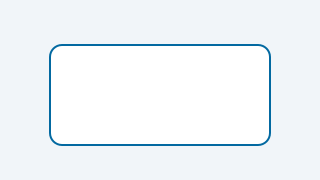

In [2]:
FONT = "Arial, Helvetica, sans-serif"
doc = svg.Document(320, 180)
doc.rect(0, 0, 320, 180, fill="#f1f5f9")
card = doc.rect(50, 45, 220, 100, rx=12, fill="white", stroke="#0369a1", stroke_width=2)
box = card.bounds()
print(box.center, box.top_left, box.bottom_right)
doc

Dots mark all nine named points.

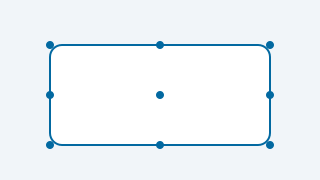

In [3]:
marks = svg.Document(root=doc.root.clone())
for name in ("top_left", "top", "top_right", "left", "center", "right", "bottom_left", "bottom", "bottom_right"):
    point = box.point(name)
    marks.circle(point.x, point.y, 4, fill="#0369a1")
marks

`align` puts one point of a shape on a point of another: the tab's bottom sits on the card's top.

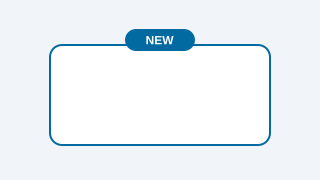

In [4]:
tab = svg.rect(0, 0, 70, 22, rx=11, fill="#0369a1")
doc += tab.align(card, "bottom", to="top", offset=(0, 6))
doc.text("NEW", font_size=12, font_weight="bold", fill="white", font_family=FONT).center = tab.center
doc

With no `to`, both shapes use the same point: the price tag goes in the bottom-right corner, 10 units in.

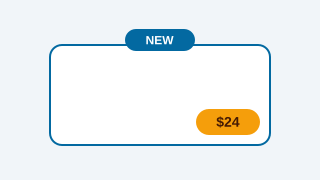

In [5]:
price = svg.rect(0, 0, 64, 26, rx=13, fill="#f59e0b")
doc += price.align(card, "bottom_right", offset=(-10, -10))
doc.text("$24", font_size=14, font_weight="bold", fill="#451a03", font_family=FONT).center = price.center
doc

Point attributes can be set directly: the icon's `center` goes near the card's left edge, the title's `center_left` beside it.

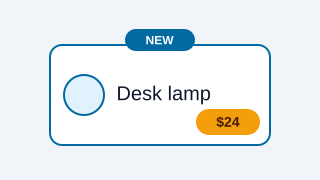

In [6]:
icon = doc.circle(0, 0, 20, fill="#e0f2fe", stroke="#0369a1", stroke_width=2)
icon.center = (box.left + 34, box.center.y)
title = doc.text("Desk lamp", font_size=20, fill="#0f172a", font_family=FONT)
title.center_left = (icon.right + 14, icon.center.y)
doc

Save it. Next: [04 Paths](../04_paths/paths.py) draws your own shapes.

In [7]:
doc.save("03_alignment.svg")